# PEMS08F — full analysis: residuals → prior → noising → training → test

this notebook tells the complete story of what we verified for **PEMS08F** (2026-06-11, experiment tag `20260610`, branch `structured-t-prior`), in plain language:

1. **the pipeline** — what the diffusion model actually sees.
2. **the residuals** — raw and normalized statistics, heavy tails, and the train-vs-val gate.
3. **the matrices** — the temporal prior $\Sigma_T$ and the sensor graph (and why the trained prior is temporal-only).
4. **the noising process** — the FCPS schedule, mixing, and an empirical check of the forward sampler.
5. **training** — loss / generation / distribution diagnostics from the six cluster runs.
6. **test results so far** — with an important caveat about a known evaluation bug.
7. **summary** — every check in one table.

quick facts for PEMS08F: **170 sensors** measuring **traffic flow** (vehicles per 5-minute interval), chronological split, **no missing data**, horizon **H = 12** steps (one hour ahead). seed 42 is shown throughout; seeds 43/44 were checked and agree wherever it matters.

> ⚠️ **caveat up front:** every *test-set* number in section 6 was produced by an eval script that rebuilt the reverse schedule from a config default ~650× larger than the value training actually used. during-training metrics are unaffected. details (and why the kron-vs-iso test table is not quotable yet) in section 6.

In [1]:
# setup: work from the repo root so src imports and relative paths resolve
import os, sys
while not os.path.exists("pyproject.toml"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

dataset = "pems08f"
seed = 42          # display seed; seeds 43/44 are checked wherever it matters

import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as sps
from scipy.optimize import brentq
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

from src.utils import paths
from src.data.adjacency import load_adjacency, compute_normalized_laplacian
from src.data.residual_dataset import train_residual_sigma
from src.diffusion.prior import load_prior, KAPPA_CAP, SPATIAL_FLATTEN
from src.diffusion.forward_fcps import FCPSSchedule, sample_R_t_given_R0, _rotate_to_eigenbasis

# every section appends its verdict here; section 7 prints the full table
summary_rows = []
def note(check, status, meaning):
    summary_rows.append((check, status, meaning))

print("dataset:", dataset, "  display seed:", seed)
print("temporal-only prior (spatial factor flattened to identity):", SPATIAL_FLATTEN)

dataset: pems08f   display seed: 42
temporal-only prior (spatial factor flattened to identity): True


## 1. the pipeline in one paragraph

a **Graph WaveNet** backbone takes the last hour of traffic and predicts the next hour. it is good but not perfect; the gap between truth and forecast is the **residual**, shape (B windows, N=170 sensors, H=12 steps), stored in **raw units** (vehicles per 5 min). the diffusion model learns to *generate* these residuals — adding a generated residual to the backbone forecast turns a point forecast into a probabilistic one.

before training, residuals are divided by **one global scalar** $\sigma_r$: the masked std of the *train* residuals, frozen and reused for val/test. that is the entire normalization — no per-sensor or per-horizon scaling. the per-horizon spread is deliberately left in the data, because the temporal prior $\Sigma_T$ is supposed to encode it (section 3).

two arms are trained per seed: **kronecker** (our method: noise shaped by $\Sigma_T$) and **isotropic** (white noise, $\sigma^2 = 1$ in unit space — the scale-matched baseline). seeds 42/43/44, per-seed backbones.

first, the residual caches on disk — keys, shapes, the missing-data mask, and that one normalization scalar:

In [2]:
npz = {sp: np.load(paths.residual_npz(dataset, sp, seed)) for sp in ["train", "val", "test"]}
print("keys:", npz["train"].files)
print()
print(f"{'split':6s} {'windows':>8s} {'shape (B,N,H)':>18s} {'dtype':>8s} {'valid frac':>10s} {'nan':>4s} {'inf':>4s}")
for sp, d in npz.items():
    R, M = d["residuals"], d["mask"]
    print(f"{sp:6s} {R.shape[0]:>8d} {str(R.shape):>18s} {str(R.dtype):>8s} "
          f"{M.mean():>10.4f} {int(np.isnan(R).sum()):>4d} {int(np.isinf(R).sum()):>4d}")

sigma_r = train_residual_sigma(dataset, seed)
print(f"\nsigma_r (masked std of TRAIN residuals, one global scalar) = {sigma_r:.4f}")
print("the cluster training log printed sigma_r=28.5671 -> match:", abs(sigma_r - 28.5671) < 5e-4)

clean = all(int(np.isnan(d["residuals"]).sum()) == 0 and int(np.isinf(d["residuals"]).sum()) == 0
            for d in npz.values())
note("residual caches clean (no nan/inf, mask fully valid, float16 on disk harmless)",
     "PASS" if clean else "FAIL",
     "the data the diffusion model trains on is exactly what we think it is")
note("sigma_r reproduces the training log (28.5671)",
     "PASS" if abs(sigma_r - 28.5671) < 5e-4 else "FAIL",
     "the local residual cache is the one the cluster runs trained on")

keys: ['residuals', 'y_pred', 'mask', 'mean', 'std']

split   windows      shape (B,N,H)    dtype valid frac  nan  inf


train     10691   (10691, 170, 12)  float16     1.0000    0    0
val        3548    (3548, 170, 12)  float16     1.0000    0    0
test       3548    (3548, 170, 12)  float16     1.0000    0    0



sigma_r (masked std of TRAIN residuals, one global scalar) = 28.5671
the cluster training log printed sigma_r=28.5671 -> match: True


the files store residuals in **float16** to halve disk size — we verified (in the meeting analysis) that this rounding is numerically harmless for every statistic we use. `mask=True` marks valid entries; on PEMS08F nothing is missing, but every average in this notebook is still mask-aware so the same code works on METR-LA.

### one concrete window, so the numbers feel real

one sensor, one window: the backbone forecast, the truth, and the residual (their gap) at +5, +30 and +60 minutes. `y_true` is not stored — it is exactly `y_pred + residual`.

In [3]:
d = npz["train"]
r0 = d["residuals"][0, 0].astype(np.float64)
yp0 = d["y_pred"][0, 0].astype(np.float64)
print("sensor 0, window 0   (units: vehicles / 5 min)")
print("step       y_true    y_pred   residual")
for h in [0, 5, 11]:
    print(f"+{(h+1)*5:>3} min  {yp0[h]+r0[h]:>8.1f}  {yp0[h]:>8.1f}  {r0[h]:>+8.1f}")

sensor 0, window 0   (units: vehicles / 5 min)
step       y_true    y_pred   residual
+  5 min      87.0      90.1      -3.1
+ 30 min      85.0      79.3      +5.7
+ 60 min      82.0      69.2     +12.8


**what this means:** every window is one hour of context → one hour of future for all 170 sensors. a positive residual = more vehicles than the backbone predicted, negative = fewer. these residuals (divided by $\sigma_r \approx 28.57$) are the *entire* training signal of the diffusion model.

## 2. the residuals

### are they gaussian? (no — and that matters)

we compute the basic statistics on all three splits: mean, std, skewness, **excess kurtosis** (how heavy the tails are; a gaussian has 0), and extreme quantiles. why it matters: the noise we diffuse toward is gaussian — if the residuals are strongly non-gaussian we have a modeling mismatch, and quantifying it is exactly what motivated the **structured heavy-tailed (student-t) pivot** on this branch.

In [4]:
def masked_stats(d):
    v = d["residuals"][d["mask"].astype(bool)].astype(np.float64)
    mu, sd = v.mean(), v.std()
    z = (v - mu) / sd
    return dict(n=v.size, mean=float(mu), std=float(sd), skew=float((z**3).mean()),
                exkurt=float((z**4).mean() - 3.0),
                q001=float(np.quantile(v, 0.001)), q999=float(np.quantile(v, 0.999)))

stats = {sp: masked_stats(npz[sp]) for sp in ["train", "val", "test"]}

print(f"{'split':6s} {'mean':>7s} {'std':>7s} {'skew':>7s} {'ex.kurt':>8s} {'q0.001':>8s} {'q0.999':>8s}")
for sp, s in stats.items():
    print(f"{sp:6s} {s['mean']:>7.2f} {s['std']:>7.2f} {s['skew']:>7.2f} {s['exkurt']:>8.1f} "
          f"{s['q001']:>8.1f} {s['q999']:>8.1f}")

kurt = stats["train"]["exkurt"]
nu_implied = 4.0 + 6.0 / kurt
print(f"\nexcess kurtosis (train) = {kurt:.1f}   (a gaussian has 0)")
print(f"moment-implied student-t dof: nu = 4 + 6/kurtosis = {nu_implied:.2f}   (hypothesis: nu ~ 4.2)")

note(f"heavy tails: train excess kurtosis {kurt:.0f}, implied student-t nu = {nu_implied:.2f}", "INFO",
     "supports the heavy-tailed pivot; nu is moment-matched, not MLE-fitted")

split     mean     std    skew  ex.kurt   q0.001   q0.999
train     1.71   28.57   -0.42     23.4   -197.9    181.0
val       1.98   28.48   -0.37     20.9   -188.9    169.2
test      1.88   27.16   -0.30     17.1   -167.2    159.4

excess kurtosis (train) = 23.4   (a gaussian has 0)
moment-implied student-t dof: nu = 4 + 6/kurtosis = 4.26   (hypothesis: nu ~ 4.2)


**what this means:** the residuals are heavily non-gaussian — excess kurtosis ≈ 23 against a gaussian's 0. if we ask "which student-t has this fourth moment?" the answer is $\nu = 4 + 6/\text{kurt} \approx 4.26$, which brackets the $\nu \approx 4.2$ we hypothesized for the pivot (across datasets the implied $\nu$ ranges 4.15–4.31). two honest caveats:

- this $\nu$ is **moment-matched, not MLE-fitted** — a proper fit comes with the pivot work;
- the residuals are also **left-skewed**. on PEMS08F (flow) the skew is mild (≈ −0.4); on the speed datasets (METR-LA, PEMS-BAY) it is strong (−1.4 to −2.8, from sudden speed-drop events). a *symmetric* t does not capture skew — known limitation of the planned prior.

now let's *see* the tails: a histogram on a log scale, against a gaussian and a student-t with the same mean and std.

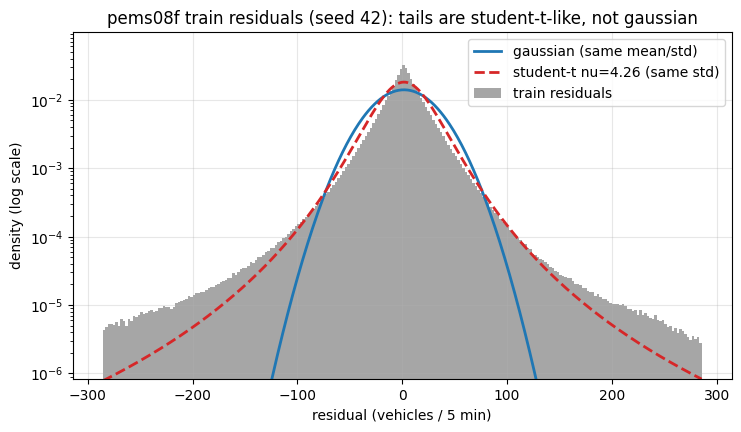

fraction of mass outside the +/-10 sigma plot window: 4.9e-04


In [5]:
v = npz["train"]["residuals"][npz["train"]["mask"].astype(bool)].astype(np.float32)
mu, sd = stats["train"]["mean"], stats["train"]["std"]
edges = np.linspace(-10 * sd, 10 * sd, 241)
counts, _ = np.histogram(v, bins=edges)
centers = 0.5 * (edges[:-1] + edges[1:])
dens = counts / (v.size * (edges[1] - edges[0]))

xx = np.linspace(edges[0], edges[-1], 600)
t_scale = sd * np.sqrt((nu_implied - 2) / nu_implied)   # so the t has the same std as the data

plt.figure(figsize=(8.5, 4.5))
plt.bar(centers, dens, width=edges[1] - edges[0], color="0.65", label="train residuals")
plt.plot(xx, sps.norm.pdf(xx, mu, sd), "C0-", lw=2, label="gaussian (same mean/std)")
plt.plot(xx, sps.t.pdf(xx, df=nu_implied, loc=mu, scale=t_scale), "C3--", lw=2,
         label=f"student-t nu={nu_implied:.2f} (same std)")
plt.yscale("log")
plt.ylim(max(dens[dens > 0].min() * 0.3, 1e-12), dens.max() * 3)
plt.xlabel("residual (vehicles / 5 min)"); plt.ylabel("density (log scale)")
plt.title(f"{dataset} train residuals (seed {seed}): tails are student-t-like, not gaussian")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print(f"fraction of mass outside the +/-10 sigma plot window: {1 - counts.sum() / v.size:.1e}")

**what this means:** on a log scale a gaussian is a parabola — the blue curve dives to nothing by ±4σ, while the data still has real mass out to ±10σ. the student-t (red dashed) tracks the tails far better. big residual events are *rare but real*, and a gaussian prior pretends they basically never happen. (the visible left-right asymmetry is the mild skew from the table.)

### the per-horizon scale, the normalization, and the gate

dividing by one scalar makes the *pooled* normalized std exactly 1.0 — but each horizon keeps its own scale: errors at +5 min are much smaller than at +60 min. that spread is the structure $D_H$ in the prior will encode.

we also re-check the **lock-in gate** from section 1 of the project: the per-horizon second moment $\delta_h = \mathrm{mean}(r_h^2)$ must agree between train and val to within 10% for every horizon ($|\delta_h^{val}/\delta_h^{train} - 1| < 0.10$). if it doesn't, a prior fitted on train is mis-scaled on val/test and calibration suffers before the model even starts.

In [6]:
H = npz["train"]["residuals"].shape[2]

def per_horizon(d):
    R, M = d["residuals"], d["mask"].astype(bool)
    delta, std = [], []
    for h in range(H):
        x = R[:, :, h][M[:, :, h]].astype(np.float64)
        delta.append(float((x ** 2).mean()))   # delta_h, the gate quantity
        std.append(float(x.std()))
    return np.array(delta), np.array(std)

gate = {}
for s in [42, 43, 44]:
    dtr = np.load(paths.residual_npz(dataset, "train", s))
    dvl = np.load(paths.residual_npz(dataset, "val", s))
    sig = train_residual_sigma(dataset, s)
    delta_tr, std_tr = per_horizon(dtr)
    delta_vl, std_vl = per_horizon(dvl)
    Rv, Mv = dvl["residuals"], dvl["mask"].astype(bool)
    rv = Rv[Mv].astype(np.float64)
    gate[s] = dict(sigma_r=sig, delta_tr=delta_tr, delta_vl=delta_vl,
                   std_tr=std_tr, std_vl=std_vl, ratio=delta_vl / delta_tr - 1.0,
                   # predict-zero references reused in section 5:
                   val_trivial=float((rv ** 2).mean() / sig ** 2),
                   val_meanabs=float(np.abs(rv).mean()),
                   val_meanabs32=float(np.abs(Rv[:32][Mv[:32]].astype(np.float64)).mean()))

_, std_te = per_horizon(npz["test"])
g = gate[seed]

print("normalized per-horizon std (train, seed 42):", np.round(g["std_tr"] / g["sigma_r"], 2))
print(f"pooled normalized std (train) = {stats['train']['std'] / sigma_r:.4f}   (1.0 by construction)")

worst = {s: float(np.abs(gate[s]["ratio"]).max()) for s in [42, 43, 44]}
gate_pass = all(w < 0.10 for w in worst.values())
print("\ngate: worst |delta_vl/delta_tr - 1| over horizons, per seed:",
      {s: round(w, 4) for s, w in worst.items()})
print("gate (<0.10 for all h, all seeds):", "PASS" if gate_pass else "FAIL")

# cross-check against the diagnostic written at extraction time
diag = json.loads((Path("results/residuals") / dataset / f"seed{seed}" / "diagnostic.json").read_text())
print("matches diagnostic.json delta_train to within:",
      f"{np.abs(np.array(diag['delta_train']) - gate[seed]['delta_tr']).max():.2e}",
      "  (its pass_overall =", str(diag["pass_overall"]) + ")")

normalized per-horizon std (train, seed 42): [0.77 0.83 0.88 0.92 0.96 0.99 1.02 1.05 1.08 1.11 1.14 1.17]
pooled normalized std (train) = 1.0000   (1.0 by construction)

gate: worst |delta_vl/delta_tr - 1| over horizons, per seed: {42: 0.0511, 43: 0.0507, 44: 0.0481}
gate (<0.10 for all h, all seeds): PASS
matches diagnostic.json delta_train to within: 3.26e-03   (its pass_overall = True)


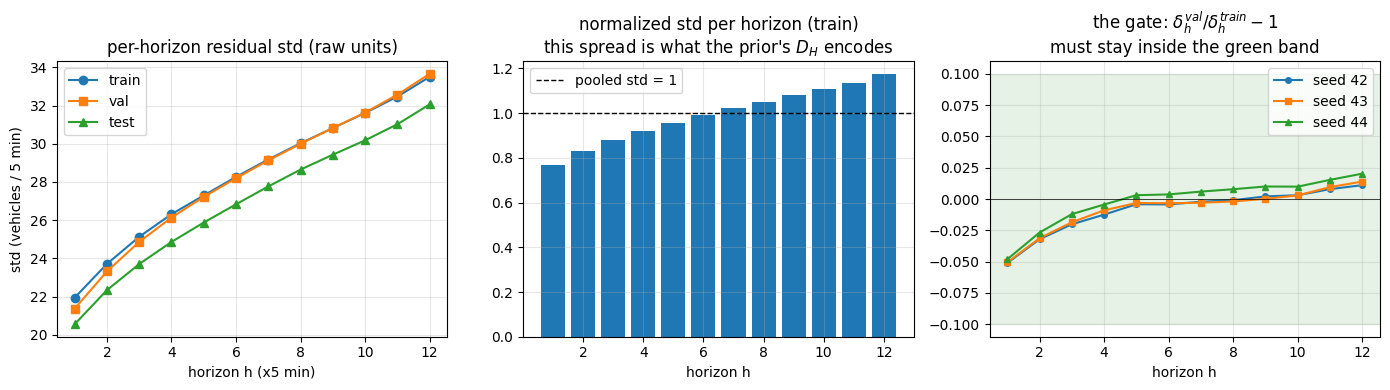

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
hh = np.arange(1, H + 1)
axes[0].plot(hh, g["std_tr"], "o-", label="train")
axes[0].plot(hh, g["std_vl"], "s-", label="val")
axes[0].plot(hh, std_te, "^-", label="test")
axes[0].set_title("per-horizon residual std (raw units)")
axes[0].set_xlabel("horizon h (x5 min)"); axes[0].set_ylabel("std (vehicles / 5 min)")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].bar(hh, g["std_tr"] / g["sigma_r"], color="C0")
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="pooled std = 1")
axes[1].set_title("normalized std per horizon (train)\nthis spread is what the prior's $D_H$ encodes")
axes[1].set_xlabel("horizon h"); axes[1].legend(); axes[1].grid(alpha=0.3)

for s, mk in zip([42, 43, 44], ["o", "s", "^"]):
    axes[2].plot(hh, gate[s]["ratio"], mk + "-", ms=4, label=f"seed {s}")
axes[2].axhspan(-0.10, 0.10, color="green", alpha=0.10)
axes[2].axhline(0, color="k", lw=0.5)
axes[2].set_title("the gate: $\\delta_h^{val}/\\delta_h^{train} - 1$\nmust stay inside the green band")
axes[2].set_xlabel("horizon h"); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

note("train-vs-val variance gate (<10% per horizon), all three seeds",
     "PASS" if gate_pass else "FAIL",
     f"worst horizon deviation {max(worst.values()):.3f}; a prior fitted on train keeps the right scale on val")

**what this means:** PEMS08F passes the gate comfortably — the worst horizon is ~5% off, well inside the 10% band, for all three seeds. the normalized per-horizon std runs from ≈ 0.77 (h1) to ≈ 1.17 (h12), so a single scalar normalization is the right call *only because* the prior carries the per-horizon scale.

for contrast: METR-LA also passes (worst 0.070), but **PEMS-BAY fails on all seeds** (worst ≈ 0.26 — its val residual std is ~12% above train, so any prior fitted on train is ~12% too small there, which predicts under-coverage on val/test). that is why PEMS-BAY is the agreed *limitation case study* while PEMS08F and METR-LA are the headline datasets.

## 3. the matrices

### the temporal prior $\Sigma_T$

instead of noising toward white noise $N(0, I)$, the forward process noises toward $N(0, \Sigma)$ with $\Sigma = \Sigma_T \otimes \Sigma_S$. for all 20260610 runs the prior is **temporal-only**: `SPATIAL_FLATTEN=True` in `src/diffusion/prior.py` sets $\Sigma_S = I$ ($\gamma = 0$). the graph-Laplacian spatial prior exists in the code but is a *dormant* path reserved for the structured-spatial A/B — GWN residuals are spatially rough, so a graph-smoothness prior would be misspecified.

$\Sigma_T = D_H^{1/2}\, R_H\, D_H^{1/2}$, where $D_H$ = the per-horizon second moments from section 2 and $R_H$ = the empirical correlation between horizons. its eigenvalues are floored so that $\mathrm{cond}(\Sigma_T) \le \kappa = 40$ — a deliberate regularizer that keeps the per-mode noise schedule trainable.

checks: symmetric and positive definite? does the horizon correlation decay smoothly with lag? does the $\kappa$-cap bind here? and do $\theta_{min}/\theta_{max}$ (the precision eigenvalues the schedule is built from) match what the cluster training log printed?

Sigma_T symmetric: True   positive definite: True
condition number: raw 16.2 -> after cap 16.2   (cap kappa=40 floors 0/12 eigenvalues here)
theta range [0.1619, 2.62]   (training log printed 0.1619 / 2.62 -> match: True)


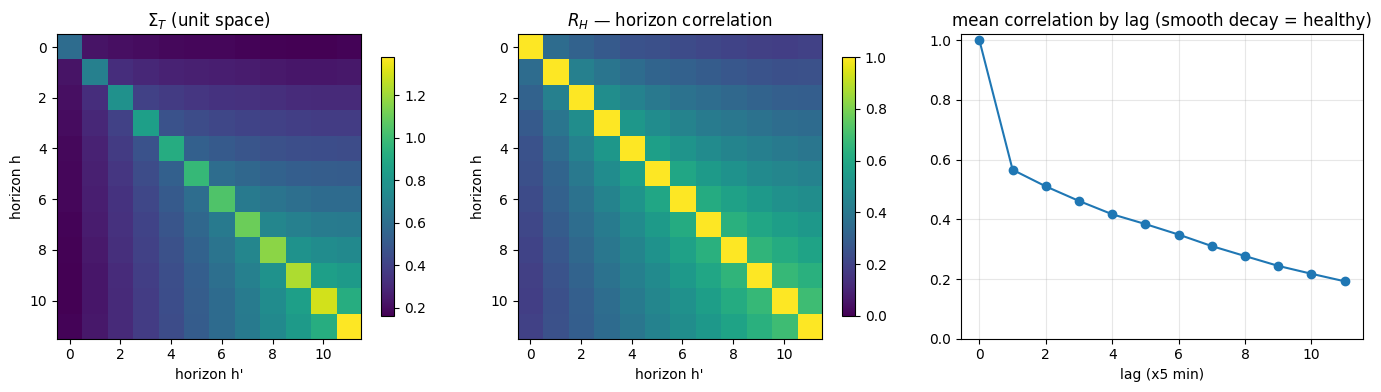

In [8]:
prior_kron = load_prior(dataset, "kronecker", seed)
D_sqrt = np.sqrt(prior_kron.delta_h)
Sigma_T = (D_sqrt[:, None] * prior_kron.R_H) * D_sqrt[None, :]   # pre-cap, unit space
mu_raw = np.linalg.eigvalsh(Sigma_T)

cond_raw = float(mu_raw.max() / mu_raw.min())
cond_cap = float(prior_kron.mu_T.max() / prior_kron.mu_T.min())
n_floored = int((mu_raw < mu_raw.max() / KAPPA_CAP).sum())
theta_min, theta_max = float(prior_kron.theta.min()), float(prior_kron.theta.max())

sym_ok = bool(np.abs(Sigma_T - Sigma_T.T).max() < 1e-12)
psd_ok = bool(mu_raw.min() > 0)
print("Sigma_T symmetric:", sym_ok, "  positive definite:", psd_ok)
print(f"condition number: raw {cond_raw:.1f} -> after cap {cond_cap:.1f}   "
      f"(cap kappa={KAPPA_CAP:.0f} floors {n_floored}/12 eigenvalues here)")
theta_ok = abs(theta_min - 0.1619) < 5e-4 and abs(theta_max - 2.62) < 5e-2
print(f"theta range [{theta_min:.4f}, {theta_max:.2f}]   "
      f"(training log printed 0.1619 / 2.62 -> match: {theta_ok})")

# how fast does the horizon correlation decay with lag?
lag_corr = np.array([np.mean([prior_kron.R_H[i, i + d] for i in range(H - d)]) for d in range(H)])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
im0 = axes[0].imshow(Sigma_T, cmap="viridis")
axes[0].set_title("$\\Sigma_T$ (unit space)"); plt.colorbar(im0, ax=axes[0], shrink=0.85)
im1 = axes[1].imshow(prior_kron.R_H, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("$R_H$ — horizon correlation"); plt.colorbar(im1, ax=axes[1], shrink=0.85)
for ax in axes[:2]:
    ax.set_xlabel("horizon h'"); ax.set_ylabel("horizon h")
axes[2].plot(np.arange(H), lag_corr, "o-")
axes[2].set_title("mean correlation by lag (smooth decay = healthy)")
axes[2].set_xlabel("lag (x5 min)"); axes[2].set_ylim(0, 1.02); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

note(f"Sigma_T healthy: symmetric PSD, smooth lag decay, cond {cond_raw:.0f} < cap {KAPPA_CAP:.0f}",
     "PASS" if (sym_ok and psd_ok and n_floored == 0) else "FAIL",
     "the kappa-cap does NOT bind on pems08f - the real horizon correlation is kept untouched")

**what this means:** $\Sigma_T$ is a clean empirical covariance: variances grow with horizon (the diagonal), nearby horizons are strongly correlated, and the correlation decays smoothly with lag. condition number ≈ 16, far below the cap of 40 — so on PEMS08F the cap is inert and the prior is exactly the data's own temporal covariance. (the cap only bites on PEMS-BAY: raw condition 161, 8 of 12 eigenvalues floored.) $\theta_{min}, \theta_{max}$ reproduce the training log digit-for-digit, so the prior we inspect here is the prior the cluster trained with.

### the sensor graph (used by the denoiser, dormant in the prior)

the road graph still matters: the denoiser network uses graph convolutions, and the structured-spatial A/B will need a healthy Laplacian. two ways to count connected components: **BFS on the graph** (ground truth) vs **counting zero Laplacian eigenvalues**. these can disagree: an isolated (zero-degree) sensor gets Laplacian row $e_i$ via the `d > 0` guard in `src/data/adjacency.py`, parking it at eigenvalue **1**, not 0 — so the eigenvalue count *undercounts* components whenever isolated sensors exist. always trust BFS.

sensors: 170   undirected edges: 274
BFS connected components: 1   (sizes: [170])   isolated sensors: 0
zero laplacian eigenvalues (<1e-8): 1   -> agrees with BFS here: True
spectral gap lambda_2 = 0.0105


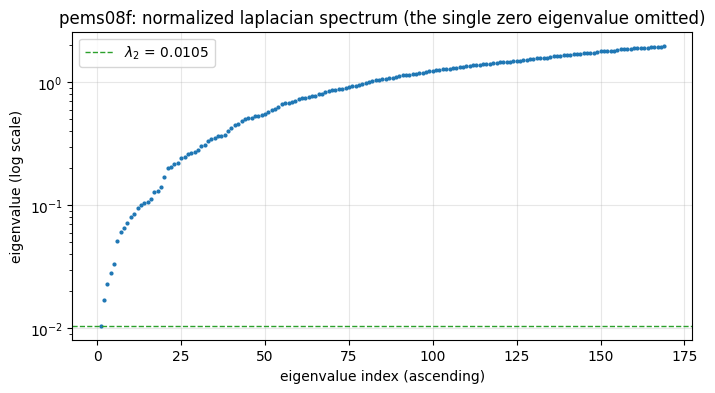

In [9]:
A_raw = load_adjacency(dataset).astype(np.float64)
A = A_raw.copy(); np.fill_diagonal(A, 0.0); A = (A + A.T) / 2.0
deg = A.sum(axis=1)
n_iso = int((deg == 0).sum())
n_comp, labels = connected_components(csr_matrix(A > 0), directed=False)
sizes = np.sort(np.bincount(labels))[::-1]

L = compute_normalized_laplacian(A_raw)
evals = np.linalg.eigvalsh(L)
n_zero = int((evals < 1e-8).sum())

print(f"sensors: {A.shape[0]}   undirected edges: {int(np.count_nonzero(np.triu(A, 1)))}")
print(f"BFS connected components: {n_comp}   (sizes: {sizes.tolist()})   isolated sensors: {n_iso}")
print(f"zero laplacian eigenvalues (<1e-8): {n_zero}   -> agrees with BFS here: {n_zero == n_comp}")
print(f"spectral gap lambda_2 = {evals[1]:.4f}")

plt.figure(figsize=(8, 4))
plt.semilogy(np.arange(1, len(evals)), np.maximum(evals[1:], 1e-12), ".", ms=4)
plt.axhline(evals[1], color="C2", ls="--", lw=1, label=f"$\\lambda_2$ = {evals[1]:.4f}")
plt.title(f"{dataset}: normalized laplacian spectrum (the single zero eigenvalue omitted)")
plt.xlabel("eigenvalue index (ascending)"); plt.ylabel("eigenvalue (log scale)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

graph_ok = (n_comp == 1 and n_iso == 0)
note("sensor graph connected (BFS: 1 component of 170, no isolated sensors)",
     "PASS" if graph_ok else "FAIL",
     "no graph repair needed before the structured-spatial A/B on this dataset")

**what this means:** PEMS08F is the easy case — one connected component, no isolated sensors, so BFS and the eigenvalue count agree (both say 1). on the other two datasets they *disagree by design*: METR-LA is a giant component of 206 **+ 1 isolated sensor**, PEMS-BAY is 319 **+ 6 isolated sensors**, and those singletons sit at eigenvalue 1 because of the `d > 0` guard, so naive zero-eigenvalue counting reports "1 component" there. benign singletons, not fragmentation — but the structured-spatial arm gives isolated sensors an effectively independent (temporal-only) prior, so this must be kept in mind for the A/B.

## 4. the noising process (FCPS schedule)

the forward process is an OU flow toward the prior: in the prior's eigenbasis each mode $k$ decays as $\exp(-\bar c(t)\,\theta_k)$ and its noise variance approaches the stationary value $1/\theta_k$, where $\bar c(t)$ is the integrated rate of the **FCPS schedule** $c(t) = c_{min} + k\,(t/T)^\alpha$ (so $\bar c(T) = c_0$). slow modes (small $\theta$) must still be fully mixed by $t = T$, which needs $2\,\bar c(T)\,\theta_{min} \gtrsim 5$.

**important quirk:** training *ignores* the `--c-0` CLI flag and auto-derives $c_0 = 5/\theta_{min}$ (`FCPSSchedule.for_prior`), making the mixing condition hold with a 2× margin by construction. `config.json` faithfully records the ignored CLI default — `c_0 = 20000` — which was *never used in training*. remember this number: it comes back in section 6.

c_0 auto-derived:  kronecker 30.89 (training log: 30.9),  isotropic 5.00
config.json records c_0 = 20000   <- the IGNORED CLI default, never used in training

mixing condition 2*c_bar(T)*theta_min = 10.00   (target >= 5 -> margin x2.0, by construction)
99%-mixed times: slowest mode t* = 0.907, fastest t* = 0.638, isotropic t* = 0.907


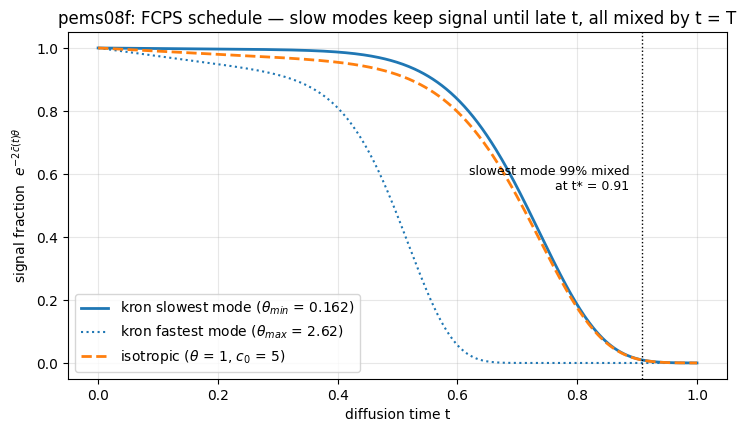

In [10]:
sch_kron = FCPSSchedule.for_prior(prior_kron)         # exactly what train_diffusion.py builds
prior_iso = load_prior(dataset, "isotropic", seed)
sch_iso = FCPSSchedule.for_prior(prior_iso)

cfg = json.loads(Path(f"results/diffusion/20260610/{dataset}/kronecker/seed{seed}/config.json").read_text())
print(f"c_0 auto-derived:  kronecker {sch_kron.c_0:.2f} (training log: 30.9),  isotropic {sch_iso.c_0:.2f}")
print(f"config.json records c_0 = {cfg['c_0']:.0f}   <- the IGNORED CLI default, never used in training")

mix = 2.0 * float(sch_kron.c_bar(1.0)) * theta_min
print(f"\nmixing condition 2*c_bar(T)*theta_min = {mix:.2f}   (target >= 5 -> margin x{mix/5:.1f}, by construction)")

def t_star(theta, sch):
    # the time where a mode is 99% mixed in variance: exp(-2 c_bar(t) theta) = 0.01
    target = np.log(100.0) / (2.0 * theta)
    return brentq(lambda t: float(sch.c_bar(t)) - target, 0.0, sch.T)

ts_slow, ts_fast = t_star(theta_min, sch_kron), t_star(theta_max, sch_kron)
ts_iso = t_star(1.0, sch_iso)
print(f"99%-mixed times: slowest mode t* = {ts_slow:.3f}, fastest t* = {ts_fast:.3f}, isotropic t* = {ts_iso:.3f}")

tt = np.linspace(0, 1, 400)
cb = np.asarray(sch_kron.c_bar(tt))
plt.figure(figsize=(8.5, 4.5))
plt.plot(tt, np.exp(-2 * cb * theta_min), "C0-", lw=2,
         label=f"kron slowest mode ($\\theta_{{min}}$ = {theta_min:.3f})")
plt.plot(tt, np.exp(-2 * cb * theta_max), "C0:", lw=1.5,
         label=f"kron fastest mode ($\\theta_{{max}}$ = {theta_max:.2f})")
plt.plot(tt, np.exp(-2 * np.asarray(sch_iso.c_bar(tt)) * 1.0), "C1--", lw=2,
         label="isotropic ($\\theta$ = 1, $c_0$ = 5)")
plt.axvline(ts_slow, color="k", ls=":", lw=1)
plt.text(ts_slow - 0.02, 0.55, f"slowest mode 99% mixed\nat t* = {ts_slow:.2f}", fontsize=9, ha="right")
plt.xlabel("diffusion time t"); plt.ylabel("signal fraction  $e^{-2\\bar{c}(t)\\theta}$")
plt.title(f"{dataset}: FCPS schedule — slow modes keep signal until late t, all mixed by t = T")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

note(f"FCPS schedule: c_0 auto-derived = {sch_kron.c_0:.2f} (matches log), mixing margin x{mix/5:.0f}",
     "PASS" if abs(mix - 10.0) < 1e-6 else "FAIL",
     f"slowest mode 99%-mixed at t* = {ts_slow:.2f}; config.json's c_0=20000 is an ignored default")

**what this means:** the schedule does exactly what FCPS is designed for — fast (high-frequency) temporal modes are destroyed early, the slowest mode holds on to its signal until $t^* \approx 0.91$, and *everything* is fully mixed by $t=T$ with a 2× safety margin. the isotropic arm has a single mode at $\theta = 1$ with $c_0 = 5$, mixing along the same profile. note the two arms see genuinely **different forward processes** — which is why their training losses cannot be compared to each other (section 5).

### does the forward sampler actually do this?

theory is one thing; we also verify the *code*. we take real val residuals, push them through the actual training code path (`sample_R_t_given_R0`), and compare the per-horizon mean decay and noise variance against the closed form, at MC precision. subsampled here for speed (256 windows, 3 values of $t$, 4 noise draws — the full check with 512 windows × 5 $t$'s × both priors was run in the meeting analysis and passed with worst pooled z = 3.33 over 360 tests). at $t = 1$ this doubles as a **stationarity check** (variance must equal $1/\theta$).

context: an einsum index bug (`'bih'`→`'bij'`) in the torch forward sampler *was* found and fixed on 2026-06-01 (commit `ac391e9`, with a regression test); all 20260610 runs contain the fix. this empirical check is exactly the kind of test that catches that class of bug — it would show up as mean/variance distortions.

In [11]:
# route np.einsum through optimize=True for this cell (identical results, verified
# against the naive path in the meeting analysis; much faster on the (B,N,H) rotations)
_einsum = np.einsum
np.einsum = lambda *a, **k: _einsum(*a, **{"optimize": True, **k})

n_win, n_rep = 256, 4
t_grid = [0.5, 0.9, 1.0]

Rv = npz["val"]["residuals"].astype(np.float64) / sigma_r   # unit space, as in training
Rv[~npz["val"]["mask"].astype(bool)] = 0.0                  # no-op here: mask is all true
R0 = Rv[np.sort(np.random.default_rng(0).choice(Rv.shape[0], n_win, replace=False))]

print(f"{'prior':10s} {'t':>4s} {'worst |dH| (mean decay)':>24s} {'z(mean)':>8s} {'worst rel dVar':>15s} {'z(var)':>8s}")
worst_z = 0.0
for name, pr, sch in [("kronecker", prior_kron, sch_kron), ("isotropic", prior_iso, sch_iso)]:
    C0 = _rotate_to_eigenbasis(R0, pr)
    scc_h = (C0 ** 2).sum(axis=(0, 1))                       # (12,)
    rng = np.random.default_rng(1)
    for t in t_grid:
        cbar = float(sch.c_bar(t))
        Hfull = np.exp(-pr.theta * cbar)                     # (N, H); rows identical (flat spatial)
        varfull = (1.0 - np.exp(-2.0 * pr.theta * cbar)) / pr.theta
        Hth, varth = Hfull[0], varfull[0]
        sxc, sr2 = np.zeros(H), np.zeros(H)
        for _ in range(n_rep):
            Xe = _rotate_to_eigenbasis(sample_R_t_given_R0(R0, t, pr, sch, rng), pr)
            sxc += (Xe * C0).sum(axis=(0, 1))
            sr2 += ((Xe - Hfull * C0) ** 2).sum(axis=(0, 1))
        n = n_rep * R0.shape[0] * R0.shape[1]                # samples pooled per horizon
        H_emp, var_emp = sxc / (n_rep * scc_h), sr2 / n
        z_mean = float((np.abs(H_emp - Hth) / np.sqrt(varth / (n_rep * scc_h))).max())
        z_var = float((np.abs(var_emp / varth - 1.0) / np.sqrt(2.0 / n)).max())
        worst_z = max(worst_z, z_mean, z_var)
        print(f"{name:10s} {t:>4.1f} {np.abs(H_emp - Hth).max():>24.2e} {z_mean:>8.2f} "
              f"{np.abs(var_emp / varth - 1.0).max():>15.2e} {z_var:>8.2f}")

np.einsum = _einsum   # restore
n_tests = 2 * len(t_grid) * H * 2
print(f"\nworst |z| over all {n_tests} pooled tests: {worst_z:.2f}   "
      f"(expected worst under a correct sampler ~3; pass < 4.5)")
note("forward noising matches the closed form (empirical re-check, MC precision)",
     "PASS" if worst_z < 4.5 else "FAIL",
     f"worst pooled z = {worst_z:.2f}; the t=1 rows double as the stationarity check (var = 1/theta)")

prior         t  worst |dH| (mean decay)  z(mean)  worst rel dVar   z(var)


kronecker   0.5                 2.05e-03     1.20        4.93e-03     1.45
kronecker   0.9                 6.64e-03     2.69        6.96e-03     2.05
kronecker   1.0                 5.68e-03     2.21        7.50e-03     2.21


isotropic   0.5                 1.64e-03     1.79        4.93e-03     1.45


isotropic   0.9                 4.53e-03     1.96        6.96e-03     2.05
isotropic   1.0                 6.19e-03     1.93        7.50e-03     2.21

worst |z| over all 144 pooled tests: 2.69   (expected worst under a correct sampler ~3; pass < 4.5)


**what this means:** every deviation between the sampled forward marginals and the closed form is at Monte-Carlo noise level — the forward process the models were trained on is *provably* the one the math says. (the fuller meeting-analysis run also checked off-diagonal covariance leakage at $t=T$ against the analytic null: indistinguishable from MC noise, i.e. no basis/einsum bugs.)

## 5. training — the six cluster runs

all six runs for this dataset (2 priors × 3 seeds) trained on a DAIC A40 with the 200-epoch cap, patience 15. the training loss is **x0-prediction masked MSE in unit space** with $t \sim U[10^{-3}, 1]$ — the model sees a noised residual and must reconstruct the clean one. a useful floor: a model that always predicts zero scores ≈ 1.0 on this loss (PEMS08F val: 1.00 exactly). a model must beat that floor to be learning anything.

we parse the slurm logs directly (largest `.out` per run dir — earlier attempts crashed at epoch ≤ 1 before training started; no run resumed mid-training).

In [12]:
LOGDIR = Path("logs/20260610/diffusion")
RE_EPOCH = re.compile(r"^epoch (\d{3})\s+train=([\d.]+)\s+val=([\d.]+)")
RE_CURVE = re.compile(r"\[recon\] curve mae \(t->0\): (.+)")
RE_PAIR  = re.compile(r"([\d.]+):([\d.]+)")
RE_GEN   = re.compile(r"\[recon\] gen mae=([\d.]+) mse=[\d.]+ \(h3=[\d.]+, h6=[\d.]+, h12=[\d.]+\)\s+WI90=([\d.]+)\s+cov=([\d.]+)")
RE_W1    = re.compile(r"\[w1\] (\d+) clean windows x\d+ \(=([\d.]+) of val\)\s+mean W1=([\d.]+) ED=([\d.]+)")
RE_STOP  = re.compile(r"early stop at epoch (\d+) \(patience=(\d+), best_val=([\d.]+)\)")
RE_SIGMA = re.compile(r"train=\d+\s+val=\d+\s+sigma_r=([\d.]+)")
RE_C0    = re.compile(r"c_0 auto-derived = ([\d.]+)")

def parse_log(path):
    run = dict(epochs=[], train=[], val=[], recon=[], w1=[],
               stop=None, patience=15, best_val=None, sigma_r=None, c0=None, log=path.name)
    cur, curve = None, None
    for line in path.read_text().splitlines():
        if (m := RE_EPOCH.match(line)):
            cur = int(m.group(1)); run["epochs"].append(cur)
            run["train"].append(float(m.group(2))); run["val"].append(float(m.group(3)))
        elif (m := RE_CURVE.search(line)):
            curve = {float(t): float(v) for t, v in RE_PAIR.findall(m.group(1))}
        elif (m := RE_GEN.search(line)):
            run["recon"].append(dict(epoch=cur, curve=curve, mae=float(m.group(1)),
                                     wi90=float(m.group(2)), cov=float(m.group(3))))
        elif (m := RE_W1.search(line)):
            run["w1"].append(dict(epoch=cur, n=int(m.group(1)), w1=float(m.group(3)), ed=float(m.group(4))))
        elif (m := RE_STOP.search(line)):
            run["stop"], run["patience"], run["best_val"] = int(m.group(1)), int(m.group(2)), float(m.group(3))
        elif run["sigma_r"] is None and (m := RE_SIGMA.search(line)):
            run["sigma_r"] = float(m.group(1))
        elif run["c0"] is None and (m := RE_C0.search(line)):
            run["c0"] = float(m.group(1))
    return run

runs = {}
for prior_name in ["kronecker", "isotropic"]:
    for s in [42, 43, 44]:
        rundir = LOGDIR / f"diffusion_{dataset}_{prior_name}_seed{s}"
        log = max(rundir.glob("*.out"), key=lambda f: f.stat().st_size)
        runs[(prior_name, s)] = parse_log(log)

print(f"{'run':16s} {'epochs':>6s} {'stop':>5s} {'best val':>9s} {'vs pred-zero':>12s} {'c_0':>6s} {'sigma ok':>9s}")
for (pn, s), r in runs.items():
    triv = gate[s]["val_trivial"]
    sig_ok = abs(r["sigma_r"] - gate[s]["sigma_r"]) < 5e-4
    print(f"{pn:>10s} s{s}   {len(r['epochs']):>6d} {str(r['stop']):>5s} "
          f"{r['best_val']:>9.4f} {r['best_val']/triv:>11.0%} {r['c0']:>6.1f} {str(sig_ok):>9s}")

for pn in ["kronecker", "isotropic"]:
    bv = [runs[(pn, s)]["best_val"] for s in [42, 43, 44]]
    print(f"{pn}: best-val spread across seeds = {(max(bv) - min(bv)) / np.mean(bv):.1%}")

learn_ok = all(r["best_val"] / gate[s]["val_trivial"] < 0.5 for (pn, s), r in runs.items())
stop_ok = all(r["stop"] is not None for r in runs.values())
note("training: all 6 runs learn (best val 21-31% of predict-zero), all early-stopped",
     "PASS" if (learn_ok and stop_ok) else "FAIL",
     "genuine learning, no divergence, seeds agree; kron-vs-iso losses NOT comparable (different schedules)")

run              epochs  stop  best val vs pred-zero    c_0  sigma ok
 kronecker s42       51    50    0.3148         32%   30.9      True
 kronecker s43       58    57    0.3066         31%   31.6      True
 kronecker s44       50    49    0.3145         31%   31.0      True
 isotropic s42       51    50    0.2168         22%    5.0      True
 isotropic s43       58    57    0.2062         21%    5.0      True
 isotropic s44       63    62    0.2179         21%    5.0      True
kronecker: best-val spread across seeds = 2.6%
isotropic: best-val spread across seeds = 5.5%


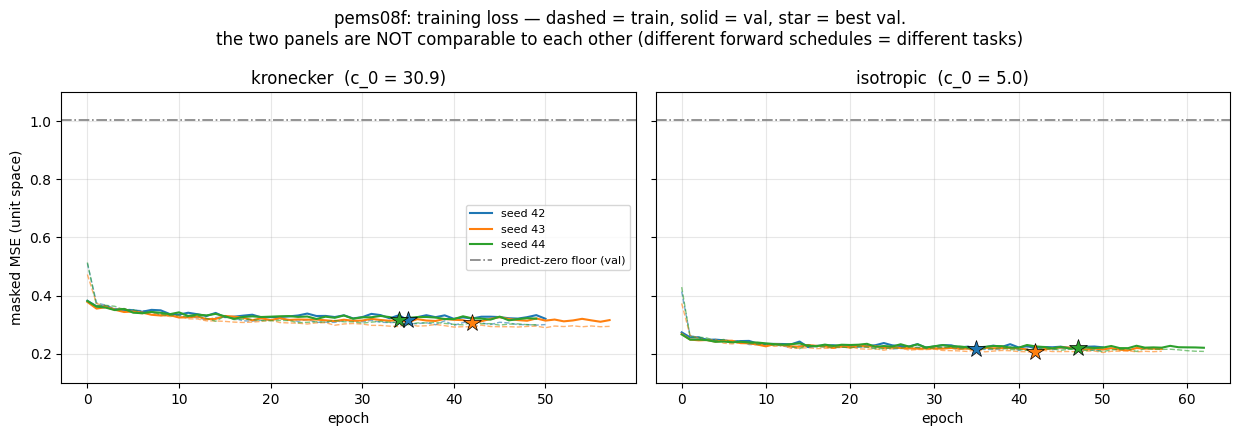

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
scol = {42: "C0", 43: "C1", 44: "C2"}
for ax, pn in zip(axes, ["kronecker", "isotropic"]):
    for s in [42, 43, 44]:
        r = runs[(pn, s)]
        ax.plot(r["epochs"], r["train"], c=scol[s], ls="--", lw=1, alpha=0.6)
        ax.plot(r["epochs"], r["val"], c=scol[s], lw=1.5, label=f"seed {s}")
        best_ep = r["stop"] - r["patience"]
        if best_ep in r["epochs"]:
            ax.plot(best_ep, r["val"][r["epochs"].index(best_ep)], "*",
                    c=scol[s], ms=13, mec="k", mew=0.5, zorder=5)
    ax.axhline(np.mean([gate[s]["val_trivial"] for s in [42, 43, 44]]),
               color="gray", ls="-.", lw=1.2, label="predict-zero floor (val)")
    ax.set_title(f"{pn}  (c_0 = {runs[(pn, 42)]['c0']:.1f})")
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("masked MSE (unit space)"); axes[0].set_ylim(0.1, 1.1)
axes[0].legend(fontsize=8)
fig.suptitle(f"{dataset}: training loss — dashed = train, solid = val, star = best val.\n"
             "the two panels are NOT comparable to each other (different forward schedules = different tasks)")
plt.tight_layout(); plt.show()

**what this means:** every run beats the predict-zero floor decisively — kron settles at ≈ 31% of the floor, iso at ≈ 21% — and train/val track each other with no divergence, with best-val agreeing across seeds to a few percent. all six stopped early (epochs 49–62), nowhere near the 200 cap.

the kron numbers being *higher* than iso means nothing by itself: with $c_0 \approx 30.9$ vs $5$, the two arms solve **different denoising problems**, so their losses live on different scales. only raw-unit metrics (below) compare across priors — and during training those show **no clear winner**.

### in-training generation checks (`[recon]`)

every 10 epochs the trainer generates from scratch on **one fixed batch — the first 32 val windows**: noise to $t=T$, then a deterministic ($\eta=0$) 100-step reverse pass, K=20 samples. two things to read correctly:

- this is effectively a **fresh conditional sample, not a round-trip** — so the "curve mae" *rising* as $t \to 0$ is the reverse path committing to one sample, not a failure (next figure).
- **gen MAE** (of the 20-sample mean, raw units) must be compared to predict-zero **on the same 32 windows** — that fixed batch is not representative of full val (here it is ~17% *easier* than average; on metr-la it is ~75% *harder*). and WI90/coverage use $\eta=0$, which structurally under-covers (~0.78 vs the 0.90 target) — not comparable to test coverage at $\eta=1$.

predict-zero MAE on the SAME 32 windows: 14.63   on full val: 17.85   (the recon batch is 18% easier than average here)


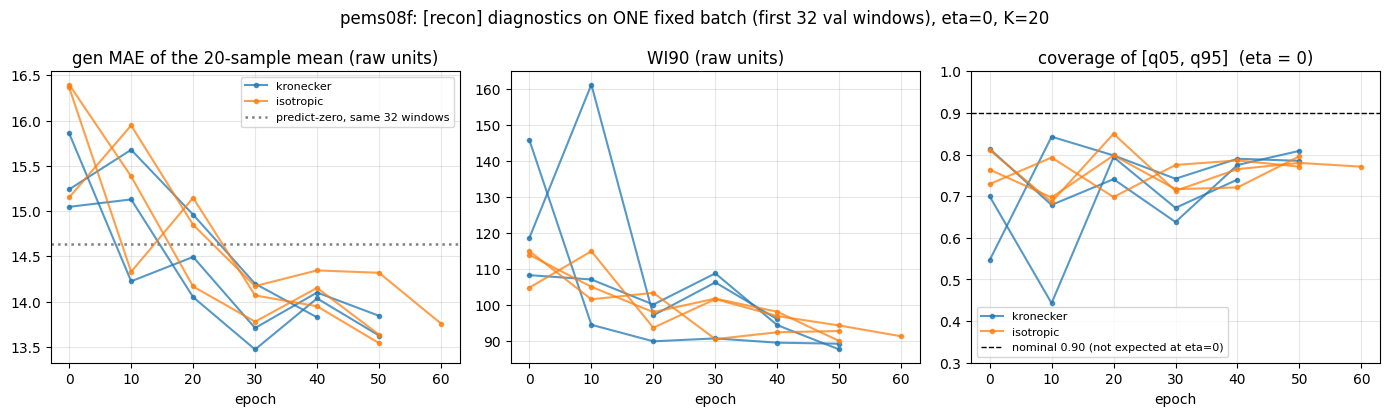

final gen MAE / predict-zero on the same 32 windows: {'kronecker': 0.94, 'isotropic': 0.93}


In [14]:
pz32 = float(np.mean([gate[s]["val_meanabs32"] for s in [42, 43, 44]]))
pzfull = float(np.mean([gate[s]["val_meanabs"] for s in [42, 43, 44]]))
print(f"predict-zero MAE on the SAME 32 windows: {pz32:.2f}   on full val: {pzfull:.2f}   "
      f"(the recon batch is {1 - pz32 / pzfull:.0%} easier than average here)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
pcol = {"kronecker": "C0", "isotropic": "C1"}
for pn in ["kronecker", "isotropic"]:
    for k, s in enumerate([42, 43, 44]):
        r = runs[(pn, s)]
        eps = [x["epoch"] for x in r["recon"]]
        lbl = pn if k == 0 else None
        axes[0].plot(eps, [x["mae"] for x in r["recon"]], "o-", c=pcol[pn], ms=3, alpha=0.75, label=lbl)
        axes[1].plot(eps, [x["wi90"] for x in r["recon"]], "o-", c=pcol[pn], ms=3, alpha=0.75, label=lbl)
        axes[2].plot(eps, [x["cov"] for x in r["recon"]], "o-", c=pcol[pn], ms=3, alpha=0.75, label=lbl)
axes[0].axhline(pz32, color="gray", ls=":", lw=1.8, label="predict-zero, same 32 windows")
axes[0].set_title("gen MAE of the 20-sample mean (raw units)"); axes[0].legend(fontsize=8)
axes[1].set_title("WI90 (raw units)")
axes[2].axhline(0.90, color="k", ls="--", lw=1, label="nominal 0.90 (not expected at eta=0)")
axes[2].set_title("coverage of [q05, q95]  (eta = 0)"); axes[2].set_ylim(0.3, 1.0); axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
plt.suptitle(f"{dataset}: [recon] diagnostics on ONE fixed batch (first 32 val windows), eta=0, K=20")
plt.tight_layout(); plt.show()

last_ratio = {pn: float(np.mean([runs[(pn, s)]["recon"][-1]["mae"] for s in [42, 43, 44]])) / pz32
              for pn in ["kronecker", "isotropic"]}
print("final gen MAE / predict-zero on the same 32 windows:",
      {pn: round(v, 2) for pn, v in last_ratio.items()})
note("gen MAE plateaus at ~0.93-0.94x predict-zero on the same windows", "INFO",
     "point accuracy ~= the backbone by construction (the model scores residuals); "
     "the value claim rests on calibration / Winkler / CRPS / W1")

**what this means:** the sample-*mean* of the generated residuals is about as accurate as predicting zero residual — i.e. point accuracy stays at the backbone's level. **that is by construction**, not a defect: the diffusion model's job is to describe the *distribution* of the residual, not to beat the backbone's mean. WI90 tightens (≈ 105–146 → 88–96) and coverage climbs toward ~0.8 as training progresses — the distributional value the model is supposed to add. (do not read the eta=0 coverage against the 0.90 target.)

the "curve mae" that the logs print along the reverse path makes the sample-commitment point visible:

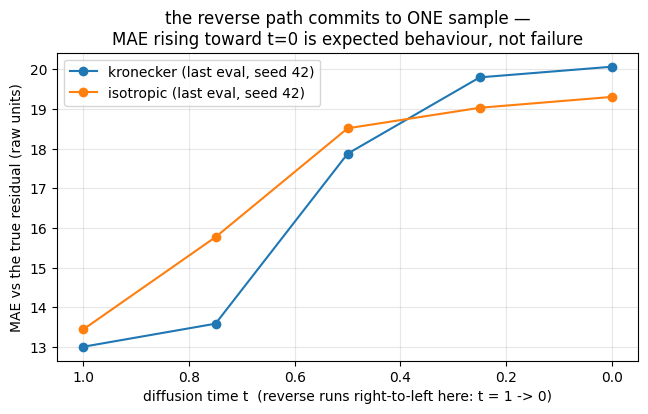

In [15]:
plt.figure(figsize=(7.5, 4))
for pn in ["kronecker", "isotropic"]:
    c = runs[(pn, seed)]["recon"][-1]["curve"]
    ts = sorted(c, reverse=True)
    plt.plot(ts, [c[t] for t in ts], "o-", label=f"{pn} (last eval, seed {seed})")
plt.gca().invert_xaxis()
plt.xlabel("diffusion time t  (reverse runs right-to-left here: t = 1 -> 0)")
plt.ylabel("MAE vs the true residual (raw units)")
plt.title("the reverse path commits to ONE sample —\nMAE rising toward t=0 is expected behaviour, not failure")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

early in the reverse pass the state is mostly noise, whose *average* sits near the data mean — closer (in MAE) to the truth than any single committed sample. as $t \to 0$ the path picks one plausible residual field, which individually differs from the truth more. a *round-trip* reconstruction would shrink toward 0; a *conditional sample* does exactly this.

### in-training distribution check (`[w1]`)

every 20 epochs: sliced Wasserstein-1 and energy distance between generated and true residuals, with $\eta = 1$ (stochastic sampling) but only **1 sample per window** — good for trends, far too noisy to rank the two priors.

w1 uses the FIRST 512 chronological clean val windows = 14% of val
(the log text '=1.00 of val' prints the fraction of val that is clean, NOT the fraction used)


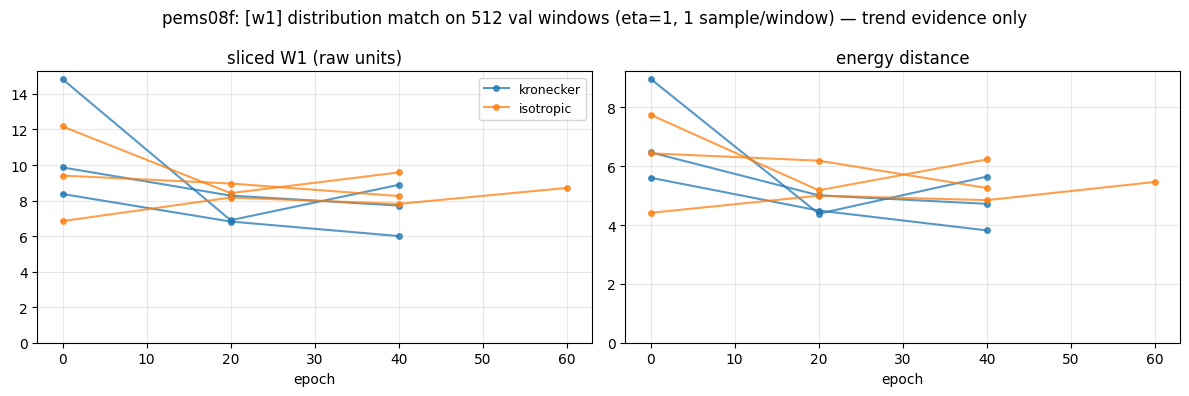

W1 first -> last improvement per run: ['28%', '40%', '22%', '12%', '21%', '-27%']   mean 16%


In [16]:
n_used = runs[("kronecker", 42)]["w1"][0]["n"]
n_val = npz["val"]["residuals"].shape[0]
print(f"w1 uses the FIRST {n_used} chronological clean val windows = {n_used / n_val:.0%} of val")
print("(the log text '=1.00 of val' prints the fraction of val that is clean, NOT the fraction used)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for pn in ["kronecker", "isotropic"]:
    for k, s in enumerate([42, 43, 44]):
        r = runs[(pn, s)]
        eps = [x["epoch"] for x in r["w1"]]
        lbl = pn if k == 0 else None
        axes[0].plot(eps, [x["w1"] for x in r["w1"]], "o-", c=pcol[pn], ms=4, alpha=0.75, label=lbl)
        axes[1].plot(eps, [x["ed"] for x in r["w1"]], "o-", c=pcol[pn], ms=4, alpha=0.75, label=lbl)
axes[0].set_title("sliced W1 (raw units)"); axes[1].set_title("energy distance")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
axes[0].legend(fontsize=9)
plt.suptitle(f"{dataset}: [w1] distribution match on {n_used} val windows (eta=1, 1 sample/window) — trend evidence only")
plt.tight_layout(); plt.show()

drops = [1 - r["w1"][-1]["w1"] / r["w1"][0]["w1"] for r in runs.values()]
print(f"W1 first -> last improvement per run: {[f'{d:.0%}' for d in drops]}   mean {np.mean(drops):.0%}")
note(f"W1 improves over training (mean drop {np.mean(drops):.0%} across the 6 runs)",
     "PASS" if np.mean(drops) > 0 else "FAIL",
     "the generated residual distribution moves toward the real one; too noisy for prior ranking")
note("kron vs iso during training: no clear winner on raw-unit metrics", "INFO",
     "gen MAE differs <5% between arms; W1 differences are inside the metric's noise")

**what this means:** the generated distribution genuinely moves toward the data distribution as training proceeds (W1 improved in 16 of the 18 runs across all datasets; dataset-mean drop here ≈ 20%). but with 1 stochastic sample per window and only a handful of eval points per run, this metric is **trend-quality evidence only** — the kron-vs-iso question needs the proper test eval (section 6, once the bug below is fixed).

> 🔧 **UPDATE (2026-06-11 16:25 CEST):** the eval-schedule bug described below was **fixed and deployed today** (commit `8803302`): `eval_diffusion.py` now rebuilds the reverse schedule via `FCPSSchedule.for_prior` (the training schedule), and `train_diffusion.py` persists the derived `c_0` into `config.json`. all 18 corrected eval jobs were resubmitted to the cluster; the old contaminated outputs were moved to `results/eval/20260610_buggy_c0/`. **the cell below now auto-loads the CORRECTED results if present, else the preserved buggy ones (clearly labeled)** — re-run it after a `sync_from_daic.sh`.

## 6. test results so far

> ⚠️ **eval bug — read before quoting any number below.**
> `scripts/eval_diffusion.py:90` rebuilds the reverse schedule from `config.json`'s `c_0 = 20000` — the **ignored CLI default** from section 4 — instead of the auto-derived training value (30.89 kron / 5.0 iso here). the reverse chain therefore ran roughly **650× (kron) / 4000× (iso) hotter** than the process the models were trained on, and *asymmetrically between the two arms*. all six `test_metrics.json` produced before today are contaminated, so the pre-fix kron-vs-iso comparison is **not quotable**. the during-training metrics of section 5 used the correct schedule and are valid. **the fix is applied** (commit `8803302`, schedule rebuilt via `FCPSSchedule.for_prior`) and the corrected eval was resubmitted; the buggy numbers are shown for completeness and the *qualitative* calibration story until the corrected run lands (see the UPDATE box above).

settings on disk: full test split, K = 30 samples, 50 reverse steps, $\eta = 1$, central 90% interval ($\alpha = 0.1$). MAE here is on the *reconstructed forecast* (backbone + sampled residual mean), so the matching backbone-only reference is the predict-zero-residual MAE, computed below. (the cell handles missing files gracefully and auto-prefers the corrected results once they sync.)

In [17]:
# read the test metrics. prefer the CORRECTED eval (post-fix, schedule rebuilt via
# FCPSSchedule.for_prior); fall back to the preserved buggy run so the qualitative
# story stays visible until the corrected numbers land. re-run after a sync_from_daic.
if "note" not in globals():            # some notebooks have no section-7 summary table
    def note(*a, **k):
        pass
corrected = Path("results/eval/20260610") / dataset
buggy = Path("results/eval/20260610_buggy_c0") / dataset

def _load(evdir):
    out = []
    for pn in ["kronecker", "isotropic"]:
        for s in [42, 43, 44]:
            f = evdir / pn / f"seed{s}" / "test_metrics.json"
            if f.exists():
                out.append(json.loads(f.read_text()))
    return out

recs = _load(corrected)
is_corrected = bool(recs)
if not recs:
    recs = _load(buggy)

if not recs:
    print(f"no test_metrics.json for {dataset} yet — corrected eval still running. PENDING.")
    note("test metrics", "PENDING",
         "corrected eval jobs submitted 2026-06-11 16:25; sync + re-run this cell once they land")
else:
    # backbone-only reference: predict zero residual on the test split, per seed
    bb = {}
    for s in sorted({r["seed"] for r in recs}):
        dte = np.load(paths.residual_npz(dataset, "test", s))
        bb[s] = float(np.abs(dte["residuals"][dte["mask"].astype(bool)].astype(np.float64)).mean())

    if is_corrected:
        print(">> CORRECTED eval (schedule = FCPSSchedule.for_prior, the training schedule) — quotable\n")
    else:
        print("!! CONTAMINATED by the c_0=20000 eval bug. corrected re-run in flight; "
              "shown for the qualitative story only !!\n")
    print(f"{'prior':10s} {'seed':>4s} {'ckpt ep':>7s} {'MAE':>7s} {'Winkler':>8s} "
          f"{'coverage':>8s} {'CRPS':>6s} {'W1*':>7s}")
    for r in recs:
        print(f"{r['prior']:10s} {r['seed']:>4d} {r['ckpt_epoch']:>7d} {r['mae']:>7.2f} "
              f"{r['winkler']:>8.1f} {r['coverage']:>8.3f} {r['crps']:>6.2f} {r['w1']:>7.2f}")
    print(f"{'backbone':10s}   (predict-zero residual)   MAE: "
          + ",  ".join(f"seed{s} = {v:.2f}" for s, v in bb.items()))

    print("\nper-prior mean +- std over seeds:")
    cov_kron = None
    for pn in ["kronecker", "isotropic"]:
        sub = [r for r in recs if r["prior"] == pn]
        if not sub:
            continue
        agg = {k: (float(np.mean([r[k] for r in sub])), float(np.std([r[k] for r in sub])))
               for k in ["mae", "winkler", "coverage", "crps", "w1"]}
        if pn == "kronecker":
            cov_kron = agg["coverage"][0]
        print(f"  {pn:10s} MAE {agg['mae'][0]:.2f}+-{agg['mae'][1]:.2f}   "
              f"Winkler {agg['winkler'][0]:.1f}+-{agg['winkler'][1]:.1f}   "
              f"coverage {agg['coverage'][0]:.3f}+-{agg['coverage'][1]:.3f}   "
              f"CRPS {agg['crps'][0]:.2f}+-{agg['crps'][1]:.2f}   W1* {agg['w1'][0]:.2f}+-{agg['w1'][1]:.2f}")

    r0 = recs[0]
    print(f"\n* W1 is computed on only the first {r0['w1_clean_windows']} clean test windows "
          f"({r0['w1_clean_windows'] / r0['n_test_windows']:.0%} of test; the stored "
          f"'w1_frac_of_test={r0['w1_frac_of_test']:.2f}' is the clean FRACTION, not the fraction used)")

    if is_corrected:
        note("test metrics (CORRECTED eval, post-fix schedule)", "OK",
             "quotable kron-vs-iso comparison; see per-prior aggregates above")
    else:
        note("test metrics present but CONTAMINATED by the c_0=20000 eval bug", "CAVEAT",
             "reverse ran hotter than training, asymmetric between arms - corrected re-run submitted, replace when it lands")
        if cov_kron is not None:
            note(f"test coverage (kron, buggy) = {cov_kron:.3f} vs 0.90 target", "CAVEAT",
                 "do not interpret until the corrected eval lands")

# a single status for notebooks that build one hardcoded summary table at the end
test_status = "PENDING" if not recs else ("OK (corrected)" if is_corrected else "CAVEAT (buggy)")


!! CONTAMINATED by the c_0=20000 eval bug. corrected re-run in flight; shown for the qualitative story only !!

prior      seed ckpt ep     MAE  Winkler coverage   CRPS     W1*
kronecker    42      35   18.61    127.4    0.916  14.44   10.35
kronecker    43      42   18.89    138.5    0.780  14.41    5.98
kronecker    44      34   18.45    129.9    0.852  14.14    7.79
isotropic    42      35   18.35    131.3    0.921  14.43   11.80
isotropic    43      42   18.57    132.6    0.848  14.27    7.97
isotropic    44      47   19.16    132.2    0.898  14.66   11.72
backbone     (predict-zero residual)   MAE: seed42 = 17.09,  seed43 = 17.34,  seed44 = 17.41

per-prior mean +- std over seeds:
  kronecker  MAE 18.65+-0.18   Winkler 131.9+-4.7   coverage 0.849+-0.056   CRPS 14.33+-0.14   W1* 8.04+-1.80
  isotropic  MAE 18.69+-0.34   Winkler 132.0+-0.6   coverage 0.889+-0.030   CRPS 14.45+-0.16   W1* 10.50+-1.79

* W1 is computed on only the first 512 clean test windows (14% of test; the stored 

**what this means (with the contamination caveat firmly attached):**

- both arms sit at MAE ≈ 18.4–19.2 vs the backbone-alone ≈ 17.1–17.4 — the sampled-mean forecast is slightly *worse* than the backbone point forecast, same as during training (the model adds distribution, not point accuracy).
- the kron arm **under-covers** (mean 0.849 vs the 0.90 target, with large seed spread — seed 43 is at 0.78) while iso is closer to nominal. on metr-la the same contaminated table had kron winning Winkler/CRPS/W1 with near-nominal coverage. none of this is quotable until the eval is re-run with the training schedule — the bug is asymmetric between the arms, so it can flip a comparison in either direction.
- the seed-43 runs of *both* arms used checkpoint epoch 42 and look worst on coverage — worth re-checking specifically after the fix.

> ⚠️ reminder: the during-training metrics (section 5) are the only currently trustworthy model-quality numbers for this dataset.

one known footnote, not a bug: the backbone's test MAE is 5–14% above the published Graph WaveNet targets (the training logs warn about this). the thesis claims concern the *residual distribution model*, not backbone SOTA — and every comparison here is against our own backbone, identically for both arms.

## 7. everything in one table

every check this notebook ran (or re-verified), with its verdict. INFO = a finding rather than a pass/fail test; CAVEAT = real result that must not be quoted yet.

In [18]:
print(f"summary — {dataset}, exp 20260610, seeds 42/43/44 (display seed {seed})\n")
wc = max(len(c) for c, _, _ in summary_rows)
print(f"{'status':8s} {'check':<{wc}s}  meaning")
print("-" * (wc + 75))
for c, st, m in summary_rows:
    print(f"{st:8s} {c:<{wc}s}  {m}")

summary — pems08f, exp 20260610, seeds 42/43/44 (display seed 42)

status   check                                                                            meaning
----------------------------------------------------------------------------------------------------------------------------------------------------------
PASS     residual caches clean (no nan/inf, mask fully valid, float16 on disk harmless)   the data the diffusion model trains on is exactly what we think it is
PASS     sigma_r reproduces the training log (28.5671)                                    the local residual cache is the one the cluster runs trained on
INFO     heavy tails: train excess kurtosis 23, implied student-t nu = 4.26               supports the heavy-tailed pivot; nu is moment-matched, not MLE-fitted
PASS     train-vs-val variance gate (<10% per horizon), all three seeds                   worst horizon deviation 0.051; a prior fitted on train keeps the right scale on val
PASS     Sigma_T healthy: symmet

### where this leaves us

PEMS08F is a **healthy headline dataset**: clean residual caches, the variance gate passes, the temporal prior is exactly the data's own horizon covariance (cap inert), the forward process is verified to MC precision, and all six runs train stably with improving distributional metrics.

**next steps:**

1. the test eval was fixed (commit `8803302`) and **resubmitted today** — re-run section 6 once the corrected results sync; only then is the kron-vs-iso test table quotable. the buggy numbers are preserved at `results/eval/20260610_buggy_c0/` for a buggy-vs-corrected A/B.
2. pems-bay corrected evals are queued behind the headline datasets (its failed variance gate makes it the limitation case study).
3. the structured heavy-tailed pivot (this branch): the kurtosis/implied-$\nu$ evidence in section 2 is the motivation for the 2×2 structure × tails grid (gaussian/student-t × iso/kron), with the caveat that the symmetric t ignores the left skew.